# 05 — Transferencia cross-asset de correctores TSMOM

> Se entrenan parámetros compartidos con SPY, QQQ, IWM, IWD, IWF y XLE, y se aplican sin fine-tuning a XLF. XLF no participa en escalas, gradientes ni selección. El estudio es exploratorio: ETFs correlacionados no constituyen una prueba general de transferencia.

## <b>Block 01 — Panel Gold y baseline causal</b>

> Cada ETF usa momentum logarítmico 126d, EWMA $\lambda=0.94$, objetivo 12%, tope 1 y retorno posterior a la decisión. El calendario y las escalas de entrenamiento se construyen solo con los seis ETFs; XLF se añade después para inferencia y evaluación. La LSTM y feedforward reciben retornos, momentum 21/63/126 y volatilidad; la única diferencia es que sus parámetros se comparten entre los seis ETFs de entrenamiento.

In [1]:
from pathlib import Path
import math, random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn
torch.set_num_threads(1)

SEED, EPOCHS, LEARNING_RATE = 42, 80, 0.01
START, LOOKBACK = pd.Timestamp('2018-01-02'), 63
FEATURES = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
LAMBDA, WARMUP, TARGET, MAX_EXPOSURE, LIMIT, COST = .94, 20, .12, 1., .20, .0005
TRAIN_ASSETS, TRANSFER = ['SPY','QQQ','IWM','IWD','IWF','XLE'], 'XLF'
CYCLES = [('2024',pd.Timestamp('2023-12-31'),pd.Timestamp('2024-01-01'),pd.Timestamp('2024-12-31')),('2025',pd.Timestamp('2024-12-31'),pd.Timestamp('2025-01-01'),pd.Timestamp('2025-12-31')),('2026',pd.Timestamp('2025-12-31'),pd.Timestamp('2026-01-01'),None)]

def root(start=Path.cwd()):
    for p in (start.resolve(), *start.resolve().parents):
        if (p/'Momentum_systematic_strategies').is_dir(): return p
    raise FileNotFoundError('No se encontró la raíz.')

ROOT=root(); GOLD=ROOT/'Momentum_systematic_strategies'/'data'/'gold'/'daily_series'/'etf'
def make_sample(symbol):
    raw=pl.read_parquet(GOLD/(symbol+'.parquet')).select('session_date','adjusted_close').sort('session_date')
    f=pd.DataFrame(raw.filter(pl.col('session_date')>=START.date()).to_dict(as_series=False)).rename(columns={'session_date':'decision_date'})
    f['decision_date']=pd.to_datetime(f['decision_date']); f['ret_1d']=f.adjusted_close.pct_change()
    for h in (21,63,126): f['mom_{}'.format(h)]=np.log(f.adjusted_close/f.adjusted_close.shift(h))
    r=f.ret_1d.to_numpy(float); v=np.full(len(f),np.nan); first=np.flatnonzero(np.isfinite(r))[0]; init=first+WARMUP-1; v[init]=np.mean(r[first:init+1]**2)
    for i in range(init+1,len(f)): v[i]=LAMBDA*v[i-1]+(1-LAMBDA)*r[i]**2
    f['ewma_vol_annual']=np.sqrt(v)*math.sqrt(252); f['baseline']=np.where(f.mom_126>0,np.minimum(MAX_EXPOSURE,TARGET/f.ewma_vol_annual),0.)
    f['return_date'],f['next_return']=f.decision_date.shift(-1),f.ret_1d.shift(-1); f['ready']=f[FEATURES].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK); f['_row']=np.arange(len(f))
    return f, f.loc[f.ready & f.next_return.notna()].copy().reset_index(drop=True)

frames,sample_list=zip(*[make_sample(s) for s in TRAIN_ASSETS+[TRANSFER]]); frames=dict(zip(TRAIN_ASSETS+[TRANSFER],frames)); raw_samples=dict(zip(TRAIN_ASSETS+[TRANSFER],sample_list))
training_dates=set.intersection(*(set(raw_samples[s].decision_date) for s in TRAIN_ASSETS)); xlf_dates=set(raw_samples[TRANSFER].decision_date); excluded_by_xlf=training_dates-xlf_dates
samples={s:raw_samples[s].loc[raw_samples[s].decision_date.isin(training_dates)].copy().reset_index(drop=True) for s in TRAIN_ASSETS}; GOLD_END=min(samples[s].return_date.max() for s in TRAIN_ASSETS); samples[TRANSFER]=raw_samples[TRANSFER].loc[raw_samples[TRANSFER].return_date<=GOLD_END].copy().reset_index(drop=True)
dates=samples[TRAIN_ASSETS[0]].decision_date.to_numpy(); assert all(np.array_equal(samples[s].decision_date.to_numpy(),dates) for s in TRAIN_ASSETS) and np.array_equal(samples[TRANSFER].decision_date.to_numpy(),dates)
print('Calendario de entrenamiento: {} decisiones; XLF excluye {}. Gold XLF hasta {}.'.format(len(dates),len(excluded_by_xlf),GOLD_END.date()))
# Correlación descriptiva pre-2024; no entra en entrenamiento ni normalización.
corr=pd.DataFrame({s:samples[s].set_index('return_date').loc[:'2023-12-31','next_return'] for s in TRAIN_ASSETS+[TRANSFER]}).corr()
print('Correlación media XLF con ETFs de entrenamiento: {:.3f}'.format(corr.loc[TRANSFER,TRAIN_ASSETS].mean())); corr.loc[[TRANSFER],TRAIN_ASSETS]

Calendario de entrenamiento: 2043 decisiones; XLF excluye 0. Gold XLF hasta 2026-11-17.
Correlación media XLF con ETFs de entrenamiento: 0.798


,SPY,QQQ,IWM,IWD,IWF,XLE
XLF,0.863074,0.673184,0.850587,0.946847,0.726089,0.728286


## <b>Block 02 — Modelos compartidos y pérdida temporal</b>

> Para cada fecha, los retornos netos se calculan por ETF y después se promedian con igual peso. Así, el Sharpe de entrenamiento corresponde a una serie temporal de cartera; no se tratan observaciones ETF-fecha como independientes.

In [2]:
class SharedFF(nn.Module):
    def __init__(self):
        super().__init__(); self.hidden,self.residual=nn.Linear(5,8),nn.Linear(8,1); nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self,x): return LIMIT*torch.tanh(self.residual(torch.tanh(self.hidden(x))).squeeze(-1))
class SharedLSTM(nn.Module):
    def __init__(self):
        super().__init__(); self.lstm=nn.LSTM(5,8,num_layers=1,batch_first=True); self.residual=nn.Linear(8,1); nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self,x):
        h,_=self.lstm(x); return LIMIT*torch.tanh(self.residual(h[:,-1,:]).squeeze(-1))
def predict(model,x,kind):
    a,t=x.shape[:2]; y=model(x.reshape(a*t,*x.shape[2:])).reshape(a,t); return y
def train(model,x,base,returns,idx,kind):
    opt=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE); index=torch.tensor(idx,dtype=torch.long)
    for _ in range(EPOCHS):
        opt.zero_grad(); p=torch.clamp(base[:,index]+predict(model,x[:,index],kind),0,1)
        turnover=(p[:,1:]-p[:,:-1]).abs(); net=p[:,1:]*returns[:,index][:,1:]-COST*turnover
        portfolio=net.mean(0); loss=-(portfolio.mean()/portfolio.std(unbiased=False).clamp_min(1e-6)*math.sqrt(252)); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    return model
pd.DataFrame({'modelo':['TSMOM','Feedforward compartido','LSTM compartida'],'parámetros entrenables':[0,57,489]})

,modelo,parámetros entrenables
0,TSMOM,0
1,Feedforward compartido,57
2,LSTM compartida,489


## <b>Block 03 — Walk-forward y transferencia a XLF</b>

> Las escalas se ajustan exclusivamente con el panel de los seis ETFs y el historial permitido. La posición heredada cubre la sesión puente antes de que el modelo nuevo pueda decidir; XLF usa los parámetros compartidos sin fine-tuning.

In [3]:
def tensors_for(train_end):
    train_idx=np.flatnonzero((samples[TRAIN_ASSETS[0]].return_date<=train_end).to_numpy()); rows=samples[TRAIN_ASSETS[0]]._row.to_numpy()
    raw_train=np.concatenate([frames[s].loc[samples[s]._row.to_numpy(),FEATURES].to_numpy(np.float32)[train_idx] for s in TRAIN_ASSETS])
    mean,std=raw_train.mean(0),np.maximum(raw_train.std(0),1e-8)
    seq,current,base,rets=[],[],[],[]
    for s in TRAIN_ASSETS+[TRANSFER]:
        full=(frames[s][FEATURES].to_numpy(np.float32)-mean)/std; r=samples[s]._row.to_numpy(); current.append(full[r]); seq.append(np.stack([full[i-LOOKBACK+1:i+1] for i in r])); base.append(samples[s].baseline.to_numpy(np.float32)); rets.append(samples[s].next_return.to_numpy(np.float32))
    return train_idx,torch.tensor(np.stack(seq[:-1])),torch.tensor(np.stack(current[:-1])),torch.tensor(np.stack(base[:-1])),torch.tensor(np.stack(rets[:-1])),torch.tensor(seq[-1][None]),torch.tensor(current[-1][None]),base[-1],rets[-1]

labels=['TSMOM XLF','Feedforward transfer','LSTM transfer']; daily_parts=[]; train_parts=[]; train_parts_before=[]; schedule=[]; previous={k:0. for k in labels}; previous_train={k:np.zeros(len(TRAIN_ASSETS)) for k in ['TSMOM','Feedforward','LSTM']}; previous_train_before={k:np.zeros(len(TRAIN_ASSETS)) for k in ['TSMOM','Feedforward','LSTM']}
for cycle,train_end,start,end in CYCLES:
    end=GOLD_END if end is None else min(end,GOLD_END); train_idx,xseq,xcur,base,rets,xlfseq,xlfcur,xlfbase,xlfret=tensors_for(train_end)
    available=samples[TRANSFER].loc[train_idx,'return_date'].max(); target=np.flatnonzero(((samples[TRANSFER].return_date>=start)&(samples[TRANSFER].return_date<=end)).to_numpy()); active=target[samples[TRANSFER].loc[target,'decision_date'].to_numpy()>available]; bridge=target[samples[TRANSFER].loc[target,'decision_date'].to_numpy()<=available]
    assert len(target)==len(active)+len(bridge) and samples[TRANSFER].loc[active,'decision_date'].min()>available
    np.random.seed(SEED);random.seed(SEED);torch.manual_seed(SEED); lstm=train(SharedLSTM(),xseq,base,rets,train_idx,'lstm'); ff=train(SharedFF(),xcur,base,rets,train_idx,'ff')
    with torch.no_grad():
        train_pos={'TSMOM':base.numpy(),'Feedforward':torch.clamp(base+predict(ff,xcur,'ff'),0,1).numpy(),'LSTM':torch.clamp(base+predict(lstm,xseq,'lstm'),0,1).numpy()}
        xlf_pos={'TSMOM XLF':xlfbase,'Feedforward transfer':np.clip(xlfbase+predict(ff,xlfcur,'ff').numpy().ravel(),0,1),'LSTM transfer':np.clip(xlfbase+predict(lstm,xlfseq,'lstm').numpy().ravel(),0,1)}
    for label,p in xlf_pos.items():
        if len(bridge): daily_parts.append(pd.DataFrame({'cycle':cycle,'return_date':samples[TRANSFER].loc[bridge,'return_date'].to_numpy(),'estrategia':label,'position':previous[label],'gross':previous[label]*xlfret[bridge],'costs':0.,'net':previous[label]*xlfret[bridge],'turnover':0.}))
        w=p[active]; turn=np.r_[abs(w[0]-previous[label]),abs(np.diff(w))]; daily_parts.append(pd.DataFrame({'cycle':cycle,'return_date':samples[TRANSFER].loc[active,'return_date'].to_numpy(),'estrategia':label,'position':w,'gross':w*xlfret[active],'costs':COST*turn,'net':w*xlfret[active]-COST*turn,'turnover':turn})); previous[label]=w[-1]
    for key,p in train_pos.items():
        # Referencia contable anterior: aplicaba el modelo nuevo durante el puente.
        w_before=p[:,target]; turn_before=np.column_stack((np.abs(w_before[:,0]-previous_train_before[key]),np.abs(np.diff(w_before,axis=1)))); net_before=w_before*rets.numpy()[:,target]-COST*turn_before; train_parts_before.append(pd.DataFrame({'cycle':cycle,'return_date':np.tile(samples[TRAIN_ASSETS[0]].loc[target,'return_date'].to_numpy(),len(TRAIN_ASSETS)),'estrategia':key,'asset':np.repeat(TRAIN_ASSETS,len(target)),'position':w_before.ravel(),'gross':(w_before*rets.numpy()[:,target]).ravel(),'costs':(COST*turn_before).ravel(),'net':net_before.ravel(),'turnover':turn_before.ravel()})); previous_train_before[key]=w_before[:,-1]
        if len(bridge):
            held=previous_train[key]; held_return=rets.numpy()[:,bridge]; train_parts.append(pd.DataFrame({'cycle':cycle,'return_date':np.tile(samples[TRAIN_ASSETS[0]].loc[bridge,'return_date'].to_numpy(),len(TRAIN_ASSETS)),'estrategia':key,'asset':np.repeat(TRAIN_ASSETS,len(bridge)),'position':np.repeat(held,len(bridge)),'gross':(held[:,None]*held_return).ravel(),'costs':0.,'net':(held[:,None]*held_return).ravel(),'turnover':0.}))
        w=p[:,active]; turn=np.column_stack((np.abs(w[:,0]-previous_train[key]),np.abs(np.diff(w,axis=1)))); gross=w*rets.numpy()[:,active]; net=gross-COST*turn; train_parts.append(pd.DataFrame({'cycle':cycle,'return_date':np.tile(samples[TRAIN_ASSETS[0]].loc[active,'return_date'].to_numpy(),len(TRAIN_ASSETS)),'estrategia':key,'asset':np.repeat(TRAIN_ASSETS,len(active)),'position':w.ravel(),'gross':gross.ravel(),'costs':(COST*turn).ravel(),'net':net.ravel(),'turnover':turn.ravel()})); previous_train[key]=w[:,-1]
    schedule.append({'ciclo':cycle,'modelo disponible tras':available.date(),'primera decisión':samples[TRANSFER].loc[active,'decision_date'].min().date(),'sesiones puente':len(bridge),'retornos XLF':len(target)})
daily=pd.concat(daily_parts).sort_values(['estrategia','return_date']).reset_index(drop=True); training_daily=pd.concat(train_parts).sort_values(['estrategia','asset','return_date']).reset_index(drop=True); training_daily_before=pd.concat(train_parts_before).sort_values(['estrategia','asset','return_date']).reset_index(drop=True); schedule=pd.DataFrame(schedule)
expected=pd.DatetimeIndex(frames[TRANSFER].loc[(frames[TRANSFER].decision_date>=pd.Timestamp('2024-01-01'))&(frames[TRANSFER].decision_date<=GOLD_END),'decision_date']); assert len(expected)==723 and daily.groupby('estrategia').return_date.apply(tuple).nunique()==1 and pd.DatetimeIndex(daily.loc[daily.estrategia=='TSMOM XLF','return_date']).equals(expected)
assert np.allclose(daily.net,daily.gross-daily.costs) and np.allclose(training_daily.net,training_daily.gross-training_daily.costs) and all(pd.DatetimeIndex(p.return_date).equals(expected) for _,p in training_daily.groupby(['estrategia','asset']))
schedule

,ciclo,modelo disponible tras,primera decisión,sesiones puente,retornos XLF
0,2024,2023-12-29,2024-01-02,1,252
1,2025,2024-12-31,2025-01-02,1,250
2,2026,2025-12-31,2026-01-02,1,221


## <b>Block 04 — Resultados de transferencia</b>

> XLF es la evaluación reservada. La tabla secundaria resume una cartera temporal igual ponderada de los seis ETFs de entrenamiento y no debe confundirse con evidencia de transferencia.

,estrategia,retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%),Δ neto diario vs TSMOM (bps)
0,Feedforward transfer,30.297,13.472,0.752,-13.173,84.413,24.417,1.221,1.087
1,LSTM transfer,16.923,11.463,0.533,-13.279,69.042,29.056,1.453,-0.510
2,TSMOM XLF,21.214,11.729,0.630,-14.554,72.583,29.877,1.494,NaN


,cycle,estrategia,retorno neto compuesto (%),Sharpe neto,max drawdown (%),costes totales (%)
0,2024,Feedforward transfer,28.141,1.882,-6.827,0.178
1,2025,Feedforward transfer,5.648,0.453,-12.606,0.370
2,2026,Feedforward transfer,-3.755,-0.313,-13.173,0.672
3,2024,LSTM transfer,18.240,1.641,-6.838,0.255
4,2025,LSTM transfer,2.780,0.291,-10.461,0.539
5,2026,LSTM transfer,-3.789,-0.315,-13.067,0.658
6,2024,TSMOM XLF,25.191,1.854,-5.947,0.242
7,2025,TSMOM XLF,1.538,0.188,-10.431,0.472
8,2026,TSMOM XLF,-4.642,-0.479,-13.714,0.780


,estrategia,retorno neto compuesto (%),Sharpe neto,volatilidad anual (%),max drawdown (%)
0,Feedforward,31.671,0.971,10.436,-10.286
1,LSTM,25.028,0.964,8.447,-6.986
2,TSMOM,21.240,0.830,8.529,-7.253


,estrategia,retorno neto compuesto (%) antes,retorno neto compuesto (%) corregido,Sharpe neto antes,Sharpe neto corregido,turnover total antes,turnover total corregido,costes totales (%) antes,costes totales (%) corregido,Δ retorno compuesto (pp),Δ costes (pp)
0,Feedforward,31.030,31.671,0.955,0.971,25.977,25.947,1.299,1.297,0.642,-0.002
1,LSTM,24.724,25.028,0.953,0.964,24.756,24.659,1.238,1.233,0.304,-0.005
2,TSMOM,20.662,21.240,0.810,0.830,22.949,22.903,1.147,1.145,0.579,-0.002


,estrategia,estado baseline en t,sesiones,Δ neto suma (%)
0,Feedforward transfer,cash,94,4.553
1,Feedforward transfer,long,629,3.309
2,LSTM transfer,cash,94,4.382
3,LSTM transfer,long,629,-8.070


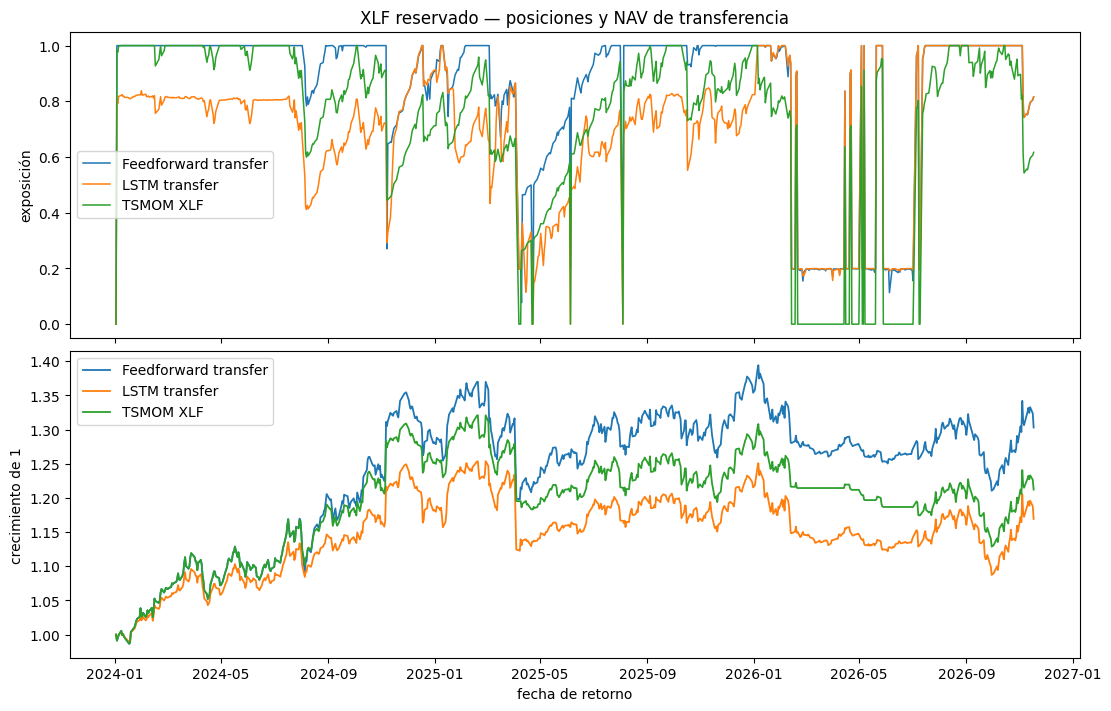

In [4]:
def metrics(part):
    n=part.net.to_numpy(); nav=np.r_[1.,np.cumprod(1+n)]; sd=n.std(ddof=0); return pd.Series({'retorno neto compuesto (%)':(nav[-1]-1)*100,'volatilidad anual (%)':sd*math.sqrt(252)*100,'Sharpe neto':n.mean()/max(sd,1e-8)*math.sqrt(252),'max drawdown (%)':(nav/np.maximum.accumulate(nav)-1).min()*100,'exposición media (%)':part.position.mean()*100,'turnover total':part.turnover.sum(),'costes totales (%)':part.costs.sum()*100})
summary=daily.groupby('estrategia',sort=False).apply(metrics,include_groups=False).reset_index(); annual=daily.groupby(['cycle','estrategia'],sort=False).apply(metrics,include_groups=False).reset_index(); base=daily.loc[daily.estrategia=='TSMOM XLF',['return_date','net']].set_index('return_date').net
for label in ['Feedforward transfer','LSTM transfer']: summary.loc[summary.estrategia==label,'Δ neto diario vs TSMOM (bps)']=(daily.loc[daily.estrategia==label].set_index('return_date').net-base).mean()*1e4
def training_portfolio(frame): return frame.groupby(['estrategia','return_date'])[['net','position','turnover','costs']].mean().reset_index()
train_portfolio=training_portfolio(training_daily); train_portfolio_before=training_portfolio(training_daily_before); train_summary=train_portfolio.groupby('estrategia').apply(metrics,include_groups=False).reset_index(); train_summary_before=train_portfolio_before.groupby('estrategia').apply(metrics,include_groups=False).reset_index()
comparison=train_summary_before.merge(train_summary,on='estrategia',suffixes=(' antes',' corregido')); comparison['Δ retorno compuesto (pp)']=comparison['retorno neto compuesto (%) corregido']-comparison['retorno neto compuesto (%) antes']; comparison['Δ costes (pp)']=comparison['costes totales (%) corregido']-comparison['costes totales (%) antes']
# Atribución XLF por estado del baseline.
b=daily.loc[daily.estrategia=='TSMOM XLF',['return_date','position','net']].rename(columns={'position':'base_position','net':'base_net'}); attr=daily.loc[daily.estrategia!='TSMOM XLF'].merge(b,on='return_date'); attr['estado baseline en t']=np.where(attr.base_position>0,'long','cash'); attr['Δ neto (%)']=(attr.net-attr.base_net)*100; attr_state=attr.groupby(['estrategia','estado baseline en t']).agg(sesiones=('return_date','size'),**{'Δ neto suma (%)':('Δ neto (%)','sum')}).reset_index()
display(summary.round(3)); display(annual[['cycle','estrategia','retorno neto compuesto (%)','Sharpe neto','max drawdown (%)','costes totales (%)']].round(3)); display(train_summary[['estrategia','retorno neto compuesto (%)','Sharpe neto','volatilidad anual (%)','max drawdown (%)']].round(3)); display(comparison[['estrategia','retorno neto compuesto (%) antes','retorno neto compuesto (%) corregido','Sharpe neto antes','Sharpe neto corregido','turnover total antes','turnover total corregido','costes totales (%) antes','costes totales (%) corregido','Δ retorno compuesto (pp)','Δ costes (pp)']].round(3)); display(attr_state.round(3))
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True,layout='constrained')
for label,p in daily.groupby('estrategia',sort=False):
    p=p.sort_values('return_date'); axes[0].plot(p.return_date,p.position,label=label,lw=1.1); axes[1].plot(p.return_date,np.cumprod(1+p.net),label=label,lw=1.3)
axes[0].set_title('XLF reservado — posiciones y NAV de transferencia'); axes[0].set_ylabel('exposición'); axes[0].set_ylim(-.05,1.05);axes[0].legend();axes[1].set_ylabel('crecimiento de 1');axes[1].set_xlabel('fecha de retorno');axes[1].legend();plt.show()

## <b>Conclusión</b>

- XLF permaneció fuera de entrenamiento, escalas y gradientes; solo sus indicadores causales se usaron en inferencia.
- El calendario de los seis ETFs tiene 2,043 decisiones y XLF no excluyó ninguna; por ello las posiciones y métricas de transferencia permanecen idénticas.
- La tabla del universo de entrenamiento ahora mantiene la posición heredada durante cada sesión puente; sus métricas cambian levemente por contabilidad, no por reentrenamiento.
- Los resultados sobre XLF describen transferencia temporal entre ETFs correlacionados, no una prueba confirmatoria de generalización.
- En esta realización, el feedforward compartido supera descriptivamente a TSMOM en XLF, mientras la LSTM compartida queda por debajo; esa diferencia no prueba que la memoria recurrente sea perjudicial ni que el feedforward generalice.
- El universo de entrenamiento se muestra por separado para evitar confundir desempeño in-sample compartido con desempeño de transferencia.
- No se modificaron arquitecturas, semillas, costes ni hiperparámetros después de observar XLF.